# Building Defect AI Notebook workflow

Run from the repository root. Expected data layout: `dataset/BD3_split/{train,val,test}/<class_name>/...`.

**Task:** classify images into the seven BD3 labels. This notebook records the method, why it is used, the result and its interpretation. Do not treat model predictions as professional inspection findings.

In [1]:
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader

from PIL import Image

# Automatically detect project root
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    ROOT = CURRENT_DIR.parent
else:
    ROOT = CURRENT_DIR

# Project paths
DATA = ROOT / "dataset" / "BD3_split"
MODEL_PATH = ROOT / "models" / "building_defect_resnet18_experiment3.pth"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Project root:", ROOT)
print("Dataset:", DATA)
print("Device:", DEVICE)

assert DATA.exists(), f"Dataset not found: {DATA}"

print("Project paths verified successfully.")

Project root: d:\02_LEARNING\03_Courses\04_Hope AI & Data Science Course\00_Sessions\Week11-Deep Learning Module\Building_Defect_AI
Dataset: d:\02_LEARNING\03_Courses\04_Hope AI & Data Science Course\00_Sessions\Week11-Deep Learning Module\Building_Defect_AI\dataset\BD3_split
Device: cuda
Project paths verified successfully.


## 1. Grad-CAM: what and why?

Grad-CAM uses the gradient of a selected class score with respect to convolutional feature maps. Averaged gradients weight the feature maps, and ReLU keeps positive contributions. The heatmap is a qualitative indication of image regions that influenced the model's scoreâ€”not a defect segmentation, severity estimate or proof of causal reasoning.

In [2]:
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from PIL import Image
CKPT = ROOT / "models" / "building_defect_resnet18_experiment3.pth"
checkpoint = torch.load(CKPT, map_location=DEVICE, weights_only=True)
class_names = checkpoint["class_names"]
model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, checkpoint["num_classes"])
model.load_state_dict(checkpoint["model_state_dict"]); model.to(DEVICE).eval()


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

## 2. Generate a heatmap for one test image

Change `IMAGE_PATH` to an image inside the held-out test set. The target layer is the final convolution in ResNet18's Layer4, matching the project's original Grad-CAM implementation.

In [3]:
IMAGE_PATH = next((DATA / "test").glob("*/*"))
original = Image.open(IMAGE_PATH).convert("RGB")
transform = models.ResNet18_Weights.DEFAULT.transforms()
x = transform(original).unsqueeze(0).to(DEVICE)
activations, gradients = {}, {}
def capture(module, inputs, output):
    activations["features"] = output
    output.register_hook(lambda grad: gradients.__setitem__("features", grad))
handle = model.layer4[-1].conv2.register_forward_hook(capture)
model.zero_grad(set_to_none=True)
logits = model(x)
idx = int(logits.argmax(1).item())
logits[0, idx].backward()
weights_cam = gradients["features"].mean(dim=(2,3), keepdim=True)
cam = F.relu((weights_cam * activations["features"]).sum(dim=1, keepdim=True))
cam = F.interpolate(cam, size=(224,224), mode="bilinear", align_corners=False)[0,0].detach().cpu().numpy()
cam = (cam-cam.min())/(cam.max()-cam.min()+1e-8)
handle.remove()
print("Image:", IMAGE_PATH, "| actual:", IMAGE_PATH.parent.name, "| prediction:", class_names[idx],
      "| confidence:", f"{torch.softmax(logits,1)[0,idx].item():.2%}")


Image: d:\02_LEARNING\03_Courses\04_Hope AI & Data Science Course\00_Sessions\Week11-Deep Learning Module\Building_Defect_AI\dataset\BD3_split\test\algae\cls00_006.jpg | actual: algae | prediction: algae | confidence: 99.98%


## 3. Visualise and interpret cautiously

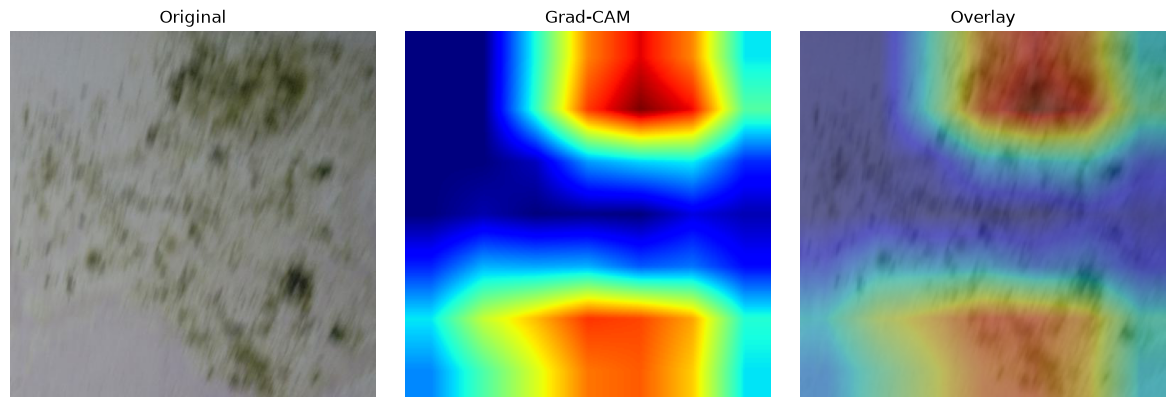

In [4]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12,4))
plt.subplot(1,3,1); plt.imshow(original); plt.title("Original"); plt.axis("off")
plt.subplot(1,3,2); plt.imshow(cam, cmap="jet"); plt.title("Grad-CAM"); plt.axis("off")
plt.subplot(1,3,3); plt.imshow(original.resize((224,224))); plt.imshow(cam, cmap="jet", alpha=.4); plt.title("Overlay"); plt.axis("off")
plt.tight_layout(); plt.show()


## 4. Interpretation of Grad-CAM Results

### What does the visualisation show?

The Grad-CAM output contains three views:

1. Original image — the input building-surface photograph.
2. Grad-CAM — the activation heatmap generated from the selected class score.
3. Overlay — the heatmap superimposed on the original image.

The heatmap contains prominent activation regions in the upper and lower portions of the image.

Rather than highlighting a small, clearly isolated surface defect, the model appears to use broader visual information from the image.

### Interpretation

This observation raises an important question:

Is the model identifying the actual surface condition, or is it also relying on contextual visual characteristics?

Potential contextual characteristics include:

- Surface colour and texture.
- Lighting and shadows.
- Background elements.
- Boundaries between different image regions.
- Environmental characteristics surrounding the visible surface.

The heatmap alone cannot establish which of these characteristics the model has learned.

### Why this matters

A classification model may achieve high test accuracy by learning visual patterns that correlate with dataset labels.

However, these patterns may not always represent the physical characteristics that a building professional would use to identify a defect.

For example, if certain defect categories are frequently photographed in similar environmental conditions, the model could partially rely on those conditions.

This creates a potential dataset-bias problem.

### Research implications

The Grad-CAM result suggests three areas for further investigation:

1. **Defect localisation:** Determine whether the model consistently attends to the visible defect rather than surrounding context.

2. **Dataset diversity:** Introduce images captured under different lighting conditions, camera distances and environmental backgrounds.

3. **Robustness testing:** Evaluate whether predictions remain consistent when irrelevant background information changes.

### Conclusion

Grad-CAM provides an additional layer of interpretability beyond classification accuracy.

In this example, the model's activation is distributed across broad image regions rather than being tightly concentrated around an identifiable defect.

This does not prove that the model is using incorrect features, but it indicates that its attention should be investigated further.

The result reinforces an important distinction:

A model that correctly classifies an image is not necessarily a model that understands the physical defect in the same way as a building inspector.

Grad-CAM is therefore useful as an investigative tool, but it cannot independently validate the model's reasoning or provide defect boundaries and severity measurements.

For future development, combining image classification with object detection or segmentation could provide more spatially specific information.

# 5. Overall Project Conclusion

This project investigated the application of deep learning and computer vision to building-surface condition classification.

Using the BD3 dataset, a seven-class image-classification system was developed using ResNet18 transfer learning.

Three training strategies were compared:

- Frozen feature extraction.
- Fine-tuning deeper network layers.
- Selective fine-tuning with early stopping.

The third experiment achieved the highest recorded test accuracy of **87.92% across 795 test images**.

Class-wise evaluation revealed that the model performs particularly well for algae and plain surfaces, while minor-crack recognition remains a significant weakness.

Grad-CAM provided an additional method for investigating the visual information influencing model predictions. Its broad activation regions highlighted the need to examine contextual bias and defect localisation.

## Key achievements

1. Developed a seven-class building-surface classification model.
2. Implemented ResNet18 transfer learning.
3. Compared three training strategies.
4. Evaluated performance using accuracy, precision, recall, F1-score and confusion matrices.
5. Implemented Grad-CAM visualisation.
6. Integrated model inference and visual explanations into a Streamlit application.

## Current limitations

- Classification is limited to the seven categories represented in the dataset.
- Minor-crack recall is relatively low.
- Near-duplicate image leakage has not yet been ruled out.
- Grad-CAM does not provide precise defect boundaries.
- Performance on images from buildings outside the dataset remains unverified.

## Future development

The next development stage could investigate:

- Object detection for identifying defect locations.
- Image segmentation for estimating defect boundaries.
- Larger and more diverse building-image datasets.
- Improved minor-crack recognition.
- Robustness testing across different environments.
- Integration with BIM workflows for recording building-condition observations.

## Final statement

The project demonstrates a practical application of transfer learning and explainable computer vision in the built environment.

It provides a foundation for developing more advanced AI-assisted building-condition assessment tools, while recognising that image classification alone is insufficient for professional building inspection.